# Análisis integral — Rusty_Baregain_mvp

**Propósito.** Analizar ventas históricas de vehículos usados y evaluar una estimación educativa de precio. La fuente cubre un periodo breve de 2016; no representa el mercado actual ni permite inferencias causales.

## Principios de este análisis

1. `data/raw/car_data.csv` es inmutable.
2. La vista descriptiva conserva todos los registros; todo hallazgo sobre precio declara que usa sólo precios observados positivos.
3. `Price` es el target: nunca se imputa para entrenar ni para evaluar.
4. Las imputaciones de features se ajustan exclusivamente con entrenamiento; prueba no aporta información al ajuste.
5. La imputación KNN por grupo se compara contra una baseline mediana/moda y sólo se adopta si la evaluación temporal la respalda.

## Cómo leer este notebook

Esta es la **etapa 1: fundamento de datos**. Su tarea no es elegir el mejor modelo, sino dejar claro qué contiene la fuente, qué registros pueden responder preguntas de precio y qué reglas se aplican antes del modelado. Cada tabla debe leerse como evidencia de calidad y trazabilidad; la etapa 2 retoma estos artefactos para evaluar predicciones sin reescribir estas reglas.


## 1. Objetivo, decisión y alcance

**Objetivo analítico.** Caracterizar la calidad y estructura de los precios históricos disponibles, y construir una referencia predictiva reproducible de `Price` a partir de atributos del vehículo.

**Decisión que apoya.** Para un comprador, la salida sirve para contrastar un vehículo con ventas/observaciones históricas comparables y decidir si merece una revisión adicional. No es una tasación vigente, una garantía de compra ni una recomendación causal.

**Alcance.** La fuente contiene observaciones capturadas entre marzo y abril de 2016. La unidad disponible no tiene identificador de transacción ni confirmación de cierre: `Price` se interpreta como **precio registrado en la observación**, no como precio final de venta verificable. El análisis no conoce descuentos, promociones, estado mecánico real, equipamiento detallado ni inflación posterior.

**Fuera de alcance.** Actualizar precios al presente, estimar descuentos comerciales, afirmar causalidad o comparar marcas/modelos como si fueran sustitutos perfectos.

> **Nota para el MVP:** el producto limita después su interfaz a vehículos ordinarios matriculados entre 1991 y 2016. Esta etapa conserva el historial válido completo para que la exclusión de vehículos potencialmente de colección sea una decisión visible de producto, no una eliminación silenciosa de la fuente.


In [1]:
import json
from datetime import datetime, timezone
from hashlib import sha256
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import display
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")
sns.set_theme(style="whitegrid", context="notebook")

def project_root():
    for candidate in [Path.cwd(), *Path.cwd().parents]:
        if (candidate / "data" / "raw" / "car_data.csv").is_file():
            return candidate
    raise FileNotFoundError("No se encontró data/raw/car_data.csv.")

ROOT = project_root()
DATA_PATH = ROOT / "data" / "raw" / "car_data.csv"
print(f"Fuente: {DATA_PATH.relative_to(ROOT)}")
print(f"SHA-256: {sha256(DATA_PATH.read_bytes()).hexdigest()}")

Fuente: data/raw/car_data.csv
SHA-256: fbe6fc8bf597d30c26f810e4768244776b65248b9617069e803b42e9515e10b0


## 2. Carga y vista de datos crudos

Se conserva la fuente tal como fue recibida. Las fechas se interpretan con formato día/mes/año de acuerdo con el archivo.

In [2]:
date_columns = ["DateCrawled", "DateCreated", "LastSeen"]
raw = pd.read_csv(DATA_PATH, parse_dates=date_columns, dayfirst=True)
raw_snapshot = raw.copy(deep=True)

raw_profile = pd.DataFrame({
    "tipo": raw.dtypes.astype(str),
    "no_nulos": raw.notna().sum(),
    "faltantes": raw.isna().sum(),
    "pct_faltantes": (100 * raw.isna().mean()).round(2),
    "distintos": raw.nunique(dropna=True),
}).sort_values("pct_faltantes", ascending=False)
print(f"Filas: {len(raw):,}; columnas: {raw.shape[1]}")
display(raw_profile)
display(raw.head())

Filas: 354,369; columnas: 16


,tipo,no_nulos,faltantes,pct_faltantes,distintos
NotRepaired,str,283215,71154,20.08,2
VehicleType,str,316879,37490,10.58,8
FuelType,str,321474,32895,9.28,7
Gearbox,str,334536,19833,5.60,2
Model,str,334664,19705,5.56,250
Price,int64,354369,0,0.00,3731
RegistrationYear,int64,354369,0,0.00,151
DateCrawled,datetime64[us],354369,0,0.00,15470
Mileage,int64,354369,0,0.00,13
Power,int64,354369,0,0.00,712


,DateCrawled,Price,VehicleType,RegistrationYear,Gearbox,Power,Model,Mileage,RegistrationMonth,FuelType,Brand,NotRepaired,DateCreated,NumberOfPictures,PostalCode,LastSeen
0,2016-03-24 11:52:00,480,NaN,1993,manual,0,golf,150000,0,petrol,volkswagen,NaN,2016-03-24,0,70435,2016-04-07 03:16:00
1,2016-03-24 10:58:00,18300,coupe,2011,manual,190,NaN,125000,5,gasoline,audi,yes,2016-03-24,0,66954,2016-04-07 01:46:00
2,2016-03-14 12:52:00,9800,suv,2004,auto,163,grand,125000,8,gasoline,jeep,NaN,2016-03-14,0,90480,2016-04-05 12:47:00
3,2016-03-17 16:54:00,1500,small,2001,manual,75,golf,150000,6,petrol,volkswagen,no,2016-03-17,0,91074,2016-03-17 17:40:00
4,2016-03-31 17:25:00,3600,small,2008,manual,69,fabia,90000,7,gasoline,skoda,no,2016-03-31,0,60437,2016-04-06 10:17:00


### Qué observar aquí

La tabla de perfil no decide todavía qué registros se eliminan. Sirve para detectar columnas incompletas, tipos inesperados y dominios que necesitarán una regla explícita. El hash impreso arriba permite comprobar que otra ejecución utilizó exactamente el mismo archivo crudo.

## 3. Datos crudos, unidad de análisis y diccionario

**Unidad de análisis:** una observación histórica de un vehículo/anuncio capturada por el proceso de recolección. No hay un identificador único de automóvil ni evidencia de que dos filas con atributos parecidos sean el mismo vehículo; por eso los duplicados se definen estrictamente sobre todas las columnas.

El diccionario distingue el significado original de cada campo de su uso posterior. Ninguna transformación altera `raw`.

In [3]:
data_dictionary = pd.DataFrame([
    ("DateCrawled", "fecha y hora de captura", "fecha/hora", "lineage y partición temporal; no predictor"),
    ("Price", "precio registrado", "EUR", "target; sólo valores > 0 para modelado"),
    ("VehicleType", "tipo de vehículo", "categoría", "predictor categórico"),
    ("RegistrationYear", "año de matriculación declarado", "año", "base para antigüedad"),
    ("Gearbox", "tipo de transmisión", "categoría", "predictor categórico"),
    ("Power", "potencia declarada", "CV", "predictor numérico discreto"),
    ("Model", "modelo declarado", "categoría", "predictor y grupo comparable"),
    ("Mileage", "kilometraje declarado", "km", "predictor numérico discreto en la fuente"),
    ("RegistrationMonth", "mes de matriculación declarado", "mes", "excluido: no aporta a la decisión definida"),
    ("FuelType", "combustible", "categoría", "predictor categórico"),
    ("Brand", "marca", "categoría", "predictor y grupo comparable"),
    ("NotRepaired", "declaración de reparación pendiente", "categoría", "predictor categórico"),
    ("DateCreated", "fecha de creación", "fecha", "lineage; excluido del modelo"),
    ("NumberOfPictures", "número de imágenes", "conteo", "excluido del modelo"),
    ("PostalCode", "código postal", "código", "excluido: geografía no disponible para el MVP"),
    ("LastSeen", "última observación", "fecha/hora", "lineage; excluido por potencial fuga"),
], columns=["campo", "definición", "unidad/tipo", "uso en este análisis"])
display(data_dictionary)

,campo,definición,unidad/tipo,uso en este análisis
0,DateCrawled,fecha y hora de captura,fecha/hora,lineage y partición temporal; no predictor
1,Price,precio registrado,EUR,target; sólo valores > 0 para modelado
2,VehicleType,tipo de vehículo,categoría,predictor categórico
3,RegistrationYear,año de matriculación declarado,año,base para antigüedad
4,Gearbox,tipo de transmisión,categoría,predictor categórico
5,Power,potencia declarada,CV,predictor numérico discreto
6,Model,modelo declarado,categoría,predictor y grupo comparable
7,Mileage,kilometraje declarado,km,predictor numérico discreto en la fuente
8,RegistrationMonth,mes de matriculación declarado,mes,excluido: no aporta a la decisión definida
9,FuelType,combustible,categoría,predictor categórico


## 4. Lineage y poblaciones analíticas

`descriptive_data` retiene todos los registros deduplicados para describir disponibilidad y calidad. `labeled_data` contiene únicamente precios observados positivos y se usa para modelar. Los precios entre 1 y 1,000 EUR se preservan: pueden ser observaciones reales de vehículos averiados o de bajo valor.

In [4]:
descriptive_data = raw.drop_duplicates().copy()
descriptive_data["PriceObserved"] = descriptive_data["Price"].gt(0)
labeled_data = descriptive_data.loc[descriptive_data["PriceObserved"]].copy()
unlabeled_data = descriptive_data.loc[~descriptive_data["PriceObserved"]].copy()

lineage = pd.DataFrame([
    {"vista": "raw", "filas": len(raw), "uso": "fuente inmutable y auditoría", "Price": "incluye 0"},
    {"vista": "descriptive_data", "filas": len(descriptive_data), "uso": "descriptivo y calidad", "Price": "incluye 0"},
    {"vista": "labeled_data", "filas": len(labeled_data), "uso": "entrenamiento y evaluación", "Price": "observado y > 0"},
    {"vista": "unlabeled_data", "filas": len(unlabeled_data), "uso": "auditoría o scoring posterior", "Price": "0 o no observado"},
])
display(lineage)
print(f"Duplicados exactos retirados antes de análisis: {len(raw) - len(descriptive_data):,}")

,vista,filas,uso,Price
0,raw,354369,fuente inmutable y auditoría,incluye 0
1,descriptive_data,354107,descriptivo y calidad,incluye 0
2,labeled_data,343337,entrenamiento y evaluación,observado y > 0
3,unlabeled_data,10770,auditoría o scoring posterior,0 o no observado


Duplicados exactos retirados antes de análisis: 262


### Cómo interpretar las poblaciones

Un precio `0` o ausente no se convierte en un precio inventado. Es útil para describir la calidad de la fuente, pero no proporciona una etiqueta válida para enseñar o evaluar un modelo de precio. Por eso el conjunto sin etiqueta se conserva para auditoría y queda fuera de la población predictiva.

## 5. Calidad y análisis descriptivo

Esta sección usa toda la vista descriptiva para calidad, y sólo `labeled_data` donde aparece una métrica de precio. Los faltantes categóricos se muestran como `unknown` únicamente para visualización; no se modifica la fuente.

,registros
precio_cero_o_no_observado,10770
año_fuera_1886_año_captura,14595
potencia_fuera_1_1000,40520
mes_fuera_1_12,37347
mileage_no_positivo,0


,Price_EUR
count,"343,337.00"
mean,"4,554.97"
std,"4,515.25"
min,1.00
1%,100.00
5%,350.00
25%,"1,200.00"
50%,"2,890.00"
75%,"6,500.00"
95%,"14,800.00"


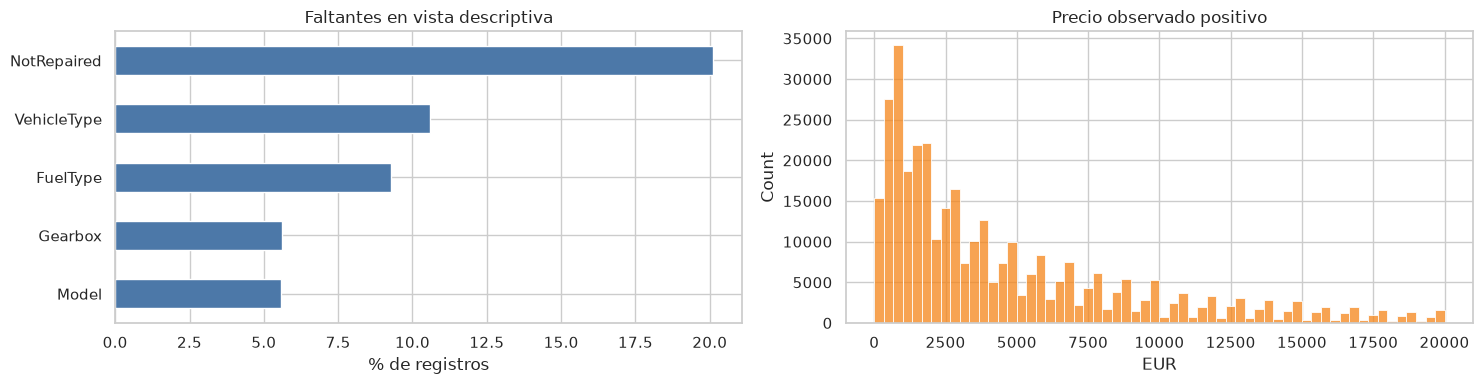

,registros
Brand,
volkswagen,76960
opel,39902
bmw,36881
mercedes_benz,32025
audi,29439
ford,25163
renault,17915
peugeot,10988
fiat,9634


In [5]:
crawl_year = descriptive_data["DateCrawled"].dt.year
quality = pd.Series({
    "precio_cero_o_no_observado": int((~descriptive_data["PriceObserved"]).sum()),
    "año_fuera_1886_año_captura": int((~descriptive_data["RegistrationYear"].between(1886, crawl_year)).sum()),
    "potencia_fuera_1_1000": int((~descriptive_data["Power"].between(1, 1000)).sum()),
    "mes_fuera_1_12": int((~descriptive_data["RegistrationMonth"].between(1, 12)).sum()),
    "mileage_no_positivo": int(descriptive_data["Mileage"].le(0).sum()),
}, name="registros")
display(quality.to_frame())

descriptive_categories = descriptive_data[["Brand", "Model", "VehicleType", "Gearbox", "FuelType", "NotRepaired"]].fillna("unknown")
missing_by_brand = (descriptive_categories.assign(Brand=descriptive_categories["Brand"].fillna("unknown"))
                    .groupby("Brand").size().sort_values(ascending=False).head(12))
price_summary = labeled_data["Price"].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).to_frame("Price_EUR")
display(price_summary)

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
missing_pct = 100 * descriptive_data.isna().mean()
missing_pct.loc[missing_pct.gt(0)].sort_values().plot.barh(ax=axes[0], color="#4C78A8")
axes[0].set(title="Faltantes en vista descriptiva", xlabel="% de registros", ylabel="")
sns.histplot(labeled_data["Price"], bins=60, ax=axes[1], color="#F58518")
axes[1].set(title="Precio observado positivo", xlabel="EUR")
plt.tight_layout(); plt.show()
display(missing_by_brand.rename("registros").to_frame())

### Lectura responsable de calidad

Las reglas de año, potencia y kilometraje identifican valores que no son utilizables como atributos analíticos; no prueban que el anuncio completo sea falso. En esta etapa se cuantifican y se conservan en la fuente. La etapa de modelado decidirá cómo representar la ausencia sin usar información de la prueba.

## 6. Contrato de features y prevención de fuga

No se elimina una variable sólo por aporte marginal individual. Se excluyen campos no disponibles al momento de estimar, con riesgo de fuga o sin valor operativo. `RegistrationMonth` queda fuera por decisión de producto. La fecha de captura se utiliza exclusivamente para construir antigüedad histórica y para la partición temporal.

In [6]:
numeric_features = ["AgeAtCrawl", "PowerForModel", "Mileage"]
categorical_features = ["VehicleType", "Gearbox", "Model", "FuelType", "Brand", "NotRepaired"]
excluded_features = {
    "Price": "target",
    "DateCrawled": "partición temporal y derivación histórica de antigüedad",
    "DateCreated": "disponibilidad/semántica no confirmada al cotizar",
    "LastSeen": "información posterior o ambigua",
    "PostalCode": "privacidad y uso geográfico no definido",
    "NumberOfPictures": "constante o sin contrato de disponibilidad",
    "RegistrationMonth": "excluida por decisión de producto",
}

def make_feature_base(frame):
    result = frame.copy()
    year_valid = result["RegistrationYear"].between(1886, result["DateCrawled"].dt.year)
    result["AgeAtCrawl"] = (result["DateCrawled"].dt.year - result["RegistrationYear"]).where(year_valid)
    result["PowerForModel"] = result["Power"].where(result["Power"].between(1, 1000))
    result["Mileage"] = result["Mileage"].where(result["Mileage"].gt(0))
    return result

model_base = make_feature_base(labeled_data).dropna(subset=["DateCrawled"]).copy()
feature_contract = pd.DataFrame([
    {"campo": field, "rol": "numérica predictiva"} for field in numeric_features
] + [
    {"campo": field, "rol": "categórica predictiva"} for field in categorical_features
] + [
    {"campo": field, "rol": f"excluida: {reason}"} for field, reason in excluded_features.items()
])
display(feature_contract)

,campo,rol
0,AgeAtCrawl,numérica predictiva
1,PowerForModel,numérica predictiva
2,Mileage,numérica predictiva
3,VehicleType,categórica predictiva
4,Gearbox,categórica predictiva
5,Model,categórica predictiva
6,FuelType,categórica predictiva
7,Brand,categórica predictiva
8,NotRepaired,categórica predictiva
9,Price,excluida: target


### Por qué existe este contrato

`AgeAtCrawl` expresa la antigüedad que tenía el vehículo en el momento histórico de captura, no su antigüedad actual. `PowerForModel` separa las potencias válidas de valores imposibles. Las columnas excluidas no son “malas”: simplemente no son apropiadas o disponibles para la consulta que realizará una persona compradora.

## 7. Artefactos de enlace para modelado

Esta etapa materializa únicamente transformaciones deterministas: deduplicación exacta, elegibilidad del target y variables derivadas. No aplica KNN, mediana/moda, codificación ni escalado aprendidos. El notebook de modelado ajustará esos pasos dentro de cada partición temporal.

In [7]:
PROCESSED_DIR = ROOT / "data" / "processed"
REPORTS_DIR = ROOT / "reports"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

descriptive_path = PROCESSED_DIR / "rusty_baregain_descriptive.csv"
modeling_path = PROCESSED_DIR / "rusty_baregain_modeling_base.csv"
dictionary_path = REPORTS_DIR / "rusty_baregain_data_dictionary.csv"
lineage_path = REPORTS_DIR / "rusty_baregain_data_lineage.json"

descriptive_data.to_csv(descriptive_path, index=False)
model_base.to_csv(modeling_path, index=False)
data_dictionary.to_csv(dictionary_path, index=False)
lineage_report = {
    "created_at_utc": datetime.now(timezone.utc).isoformat(),
    "raw_path": str(DATA_PATH.relative_to(ROOT)),
    "raw_sha256": sha256(DATA_PATH.read_bytes()).hexdigest(),
    "raw_rows": int(len(raw)),
    "descriptive_rows": int(len(descriptive_data)),
    "modeling_base_rows": int(len(model_base)),
    "target": "Price",
    "target_eligibility": "Price > 0; Price no se imputa",
    "deterministic_rules": [
        "deduplicación exacta",
        "PriceObserved = Price > 0",
        "AgeAtCrawl a partir de RegistrationYear y DateCrawled; años inválidos quedan nulos",
        "PowerForModel conserva Power en [1, 1000]; inválidos quedan nulos",
    ],
    "deferred_to_modeling": [
        "imputación aprendida", "codificación", "escalado", "selección de modelo", "evaluación temporal"
    ],
}
lineage_path.write_text(json.dumps(lineage_report, ensure_ascii=False, indent=2), encoding="utf-8")

artifacts = pd.DataFrame([
    (descriptive_path.relative_to(ROOT), len(descriptive_data), "descriptivo deduplicado"),
    (modeling_path.relative_to(ROOT), len(model_base), "base con target observado y derivaciones deterministas"),
    (dictionary_path.relative_to(ROOT), len(data_dictionary), "diccionario de campos"),
    (lineage_path.relative_to(ROOT), 1, "lineage, hash y reglas"),
], columns=["artefacto", "filas", "propósito"])
display(artifacts)

,artefacto,filas,propósito
0,data/processed/rusty_baregain_descriptive.csv,354107,descriptivo deduplicado
1,data/processed/rusty_baregain_modeling_base.csv,343337,base con target observado y derivaciones deter...
2,reports/rusty_baregain_data_dictionary.csv,16,diccionario de campos
3,reports/rusty_baregain_data_lineage.json,1,"lineage, hash y reglas"


## Cierre de etapa 1

La base queda lista para la etapa 2. Los CSV y reportes creados arriba forman el contrato reproducible entre ambas etapas. El análisis descriptivo profundo, el diagnóstico, los modelos, comparables y escenarios se desarrollan en `analisis_integral_modelado_rusty_baregain.ipynb`.

Para regenerar esta evidencia, ejecute el notebook desde un kernel limpio; la etapa 2 debe ejecutarse después de este notebook.